# Task 4 — Insight Generation from Survey Data

**Project:** clean and explore Kaggle's 2021 Machine Learning & Data Science Survey.

This notebook follows the task requirements: inspect real survey data, identify missing values and duplicates, clean inconsistent text formatting, handle categorical answers, and present findings. The bonus section creates a chart that highlights five insights.

**Important:** the file supplied by Kaggle is the original survey data. It contains legitimate missing responses and a question-description row; the data is not pre-cleaned for this project. Missing answers are not automatically errors because the survey used conditional questions. The original CSV is preserved, and cleaning happens on a working copy.

## 1. Load the original survey data

The source file is the official 2021 response CSV. Kaggle put each respondent's answers in a row, and included the question wording as the first data row. We keep the wording for reference and will exclude it from respondent calculations.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

source_file = Path("kaggle_survey_2021_responses.csv")
raw = pd.read_csv(source_file, low_memory=False)

print(f"Raw file shape: {raw.shape[0]:,} rows × {raw.shape[1]:,} columns")
display(raw.iloc[:3, :8])

Raw file shape: 25,974 rows × 369 columns


,Time from Start to Finish (seconds),Q1,Q2,Q3,Q4,Q5,Q6,Q7_Part_1
0,Duration (in seconds),What is your age (# years)?,What is your gender? - Selected Choice,In which country do you currently reside?,What is the highest level of formal education ...,Select the title most similar to your current ...,For how many years have you been writing code ...,What programming languages do you use on a reg...
1,910,50-54,Man,India,Bachelor’s degree,Other,5-10 years,Python
2,784,50-54,Man,Indonesia,Master’s degree,Program/Project Manager,20+ years,NaN


## 2. Inspect data quality issues

First separate the question-wording row. Then check exact duplicate response rows, missingness, and whitespace that could make otherwise identical category labels appear different. We report these issues before cleaning so the decisions are visible.

In [2]:
question_text = raw.iloc[0].copy()
respondents_raw = raw.iloc[1:].reset_index(drop=True)

duplicate_count = respondents_raw.duplicated().sum()
missing_cells = int(respondents_raw.isna().sum().sum())
total_cells = respondents_raw.shape[0] * respondents_raw.shape[1]
missing_percent = missing_cells / total_cells * 100

text_columns = respondents_raw.select_dtypes(include=["object", "string"]).columns
whitespace_cells = 0
for column in text_columns:
    values = respondents_raw[column].dropna()
    whitespace_cells += int(values.ne(values.str.strip()).sum())

quality_summary = pd.DataFrame({
    "Check": ["Question wording row", "Respondent rows", "Exact duplicate rows", "Missing response cells", "Cells with extra leading/trailing spaces"],
    "Result": ["1 row (not a respondent)", f"{len(respondents_raw):,}", f"{duplicate_count:,}", f"{missing_cells:,} ({missing_percent:.1f}% of cells)", f"{whitespace_cells:,}"]
})
display(quality_summary)

missing_by_question = respondents_raw.isna().sum().sort_values(ascending=False)
missing_by_question.head(12).rename_axis("Question field").to_frame("Missing responses")

,Check,Result
0,Question wording row,1 row (not a respondent)
1,Respondent rows,"25,973"
2,Exact duplicate rows,0
3,Missing response cells,"8,392,838 (87.6% of cells)"
4,Cells with extra leading/trailing spaces,"413,723"


,Missing responses
Question field,
Q36_B_Part_7,25973
Q10_Part_16,25973
Q34_B_Part_16,25973
Q7_Part_12,25973
Q9_Part_12,25973
Q32_B_Part_20,25973
Q31_B_Part_9,25973
Q30_B_Part_7,25973
Q30_B_OTHER,25973


### What the quality check means

The Kaggle file does contain a large amount of missingness, but much of it is structural: respondents were not shown every question, and multi-select questions have one column per possible answer. A blank option is not safely equivalent to “No.” We will retain missing values rather than inventing answers. Exact duplicate rows and extra text whitespace are handled separately.

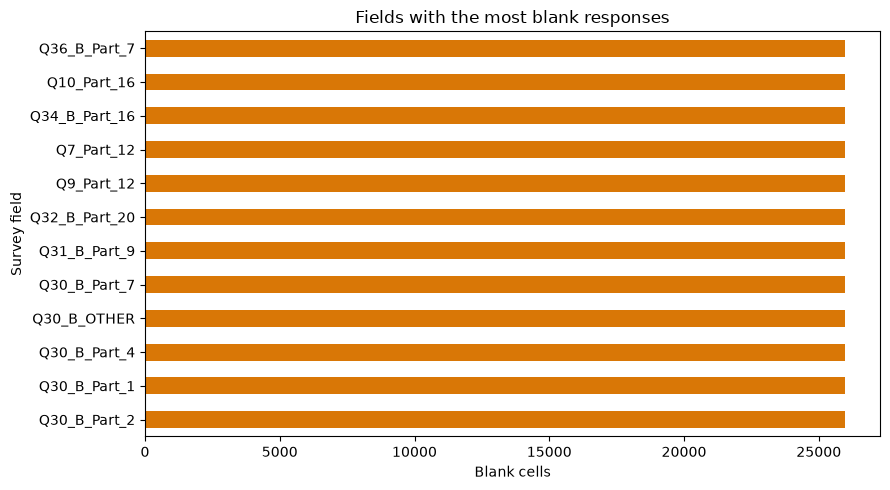

In [3]:
missing_by_question.head(12).plot(kind="barh", figsize=(9, 5), color="#d97706")
plt.gca().invert_yaxis()
plt.title("Fields with the most blank responses")
plt.xlabel("Blank cells")
plt.ylabel("Survey field")
plt.tight_layout()
plt.show()

## 3. Clean the data

Create a working copy, remove exact duplicate responses, and trim extra spaces in text values. We do not delete rows for missing answers or fill blanks. The survey includes conditional questions, so removing every incomplete row would discard valid respondent data.

In [4]:
clean = respondents_raw.drop_duplicates().copy()
rows_after_duplicates = len(clean)

for column in clean.select_dtypes(include=["object", "string"]).columns:
    clean[column] = clean[column].str.strip()

cleaning_steps = pd.DataFrame({
    "Step": ["Respondent rows before cleaning", "Exact duplicates removed", "Respondent rows after duplicate removal", "Extra-space text values standardized", "Missing responses filled"],
    "Rows / cells": [len(respondents_raw), duplicate_count, rows_after_duplicates, whitespace_cells, 0]
})
display(cleaning_steps)
print("Cleaned shape:", clean.shape)

,Step,Rows / cells
0,Respondent rows before cleaning,25973
1,Exact duplicates removed,0
2,Respondent rows after duplicate removal,25973
3,Extra-space text values standardized,413723
4,Missing responses filled,0


Cleaned shape: (25973, 369)


## 4. Handle categorical answers

Most survey fields are categories. We keep their text labels instead of assigning arbitrary integers, since values like country or job title have no numeric order. We standardize the gender response text by trimming spaces and consolidating the self-description label spelling. The original `Q2` response stays available alongside the cleaned field.

In [5]:
gender_column = "Q2"
print("Q2 question:", question_text[gender_column])

clean["Gender cleaned"] = clean[gender_column].replace({
    "Prefer to self-describe": "Self-described",
    "Prefer to self describe": "Self-described"
})

gender_summary = clean["Gender cleaned"].value_counts(dropna=False).rename_axis("Gender response").to_frame("Respondents")
display(gender_summary)
print("Q1:", question_text["Q1"])
print("Q3:", question_text["Q3"])
print("Q5:", question_text["Q5"])

Q2 question: What is your gender? - Selected Choice


,Respondents
Gender response,
Man,20598
Woman,4890
Prefer not to say,355
Nonbinary,88
Self-described,42


Q1: What is your age (# years)?
Q3: In which country do you currently reside?
Q5: Select the title most similar to your current role (or most recent title if retired): - Selected Choice


## 5. Summarize respondent profile

Use the 2021 survey fields for age (`Q1`), country (`Q3`), and current or most recent role (`Q5`). These tables show the largest groups and help describe who answered this Kaggle survey.

In [6]:
age_summary = clean["Q1"].value_counts().rename_axis("Age group").to_frame("Respondents")
country_summary = clean["Q3"].value_counts().head(10).rename_axis("Country").to_frame("Respondents")
role_summary = clean["Q5"].value_counts().head(10).rename_axis("Role").to_frame("Respondents")

display(age_summary)
display(country_summary)
display(role_summary)

,Respondents
Age group,
25-29,4931
18-21,4901
22-24,4694
30-34,3441
35-39,2504
40-44,1890
45-49,1375
50-54,964
55-59,592


,Respondents
Country,
India,7434
United States of America,2650
Other,1270
Japan,921
China,814
Brazil,751
Russia,742
Nigeria,702
United Kingdom of Great Britain and Northern Ireland,550


,Respondents
Role,
Student,6804
Data Scientist,3616
Software Engineer,2449
Other,2393
Data Analyst,2301
Currently not employed,1986
Research Scientist,1538
Machine Learning Engineer,1499
Business Analyst,968


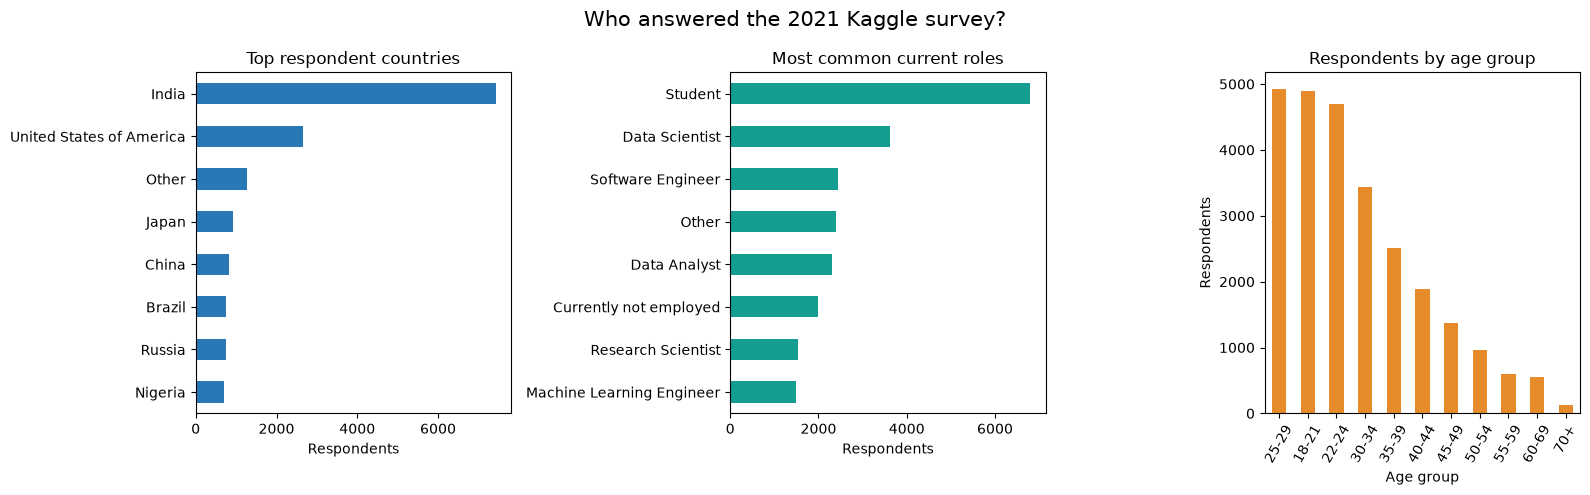

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
country_summary.head(8).sort_values("Respondents").plot.barh(ax=axes[0], legend=False, color="#2878B5")
axes[0].set_title("Top respondent countries")
axes[0].set_xlabel("Respondents")
axes[0].set_ylabel("")

role_summary.head(8).sort_values("Respondents").plot.barh(ax=axes[1], legend=False, color="#159d91")
axes[1].set_title("Most common current roles")
axes[1].set_xlabel("Respondents")
axes[1].set_ylabel("")

age_summary.plot.bar(ax=axes[2], legend=False, color="#e58b2a")
axes[2].set_title("Respondents by age group")
axes[2].set_xlabel("Age group")
axes[2].set_ylabel("Respondents")
axes[2].tick_params(axis="x", rotation=60)

plt.suptitle("Who answered the 2021 Kaggle survey?", fontsize=15)
plt.tight_layout()
plt.show()

## 6. Analyze a multiple-select question

Question `Q7` asks which programming languages respondents use regularly. Kaggle stores each selectable language in a separate column, so count non-empty selections in these columns. The option names come from the question-wording row, which avoids guessing what `Q7_Part_1` means.

In [8]:
language_columns = [column for column in clean.columns if column.startswith("Q7_")]
language_counts = clean[language_columns].notna().sum().sort_values(ascending=False)
language_names = {
    column: question_text[column].split(" - Selected Choice - ")[-1].strip()
    for column in language_columns
}
language_summary = language_counts.rename(index=language_names).rename_axis("Programming language").to_frame("Respondents selecting")
display(language_summary.sort_values("Respondents selecting", ascending=False))

,Respondents selecting
Programming language,
Python,21860
SQL,10756
C++,5535
R,5334
Java,4769
C,4709
Javascript,4332
MATLAB,2935
Other,2575


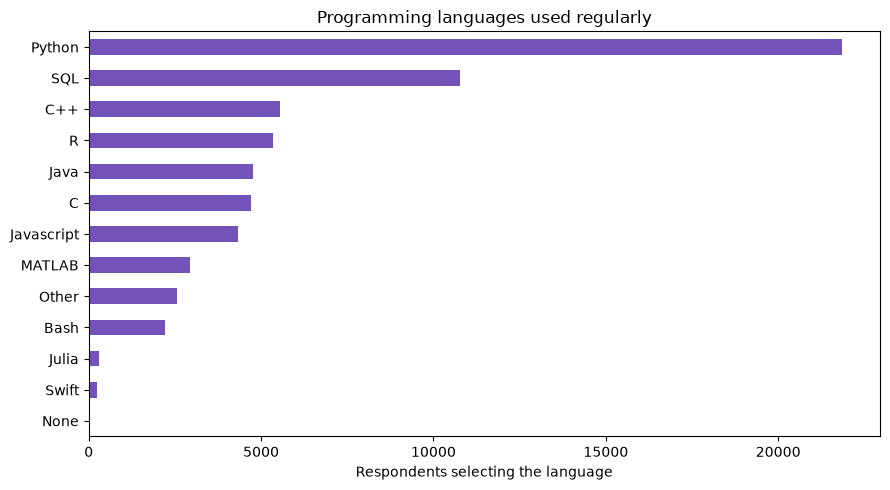

In [9]:
language_summary.sort_values("Respondents selecting").plot.barh(figsize=(9, 5), legend=False, color="#7353ba")
plt.title("Programming languages used regularly")
plt.xlabel("Respondents selecting the language")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 7. Generate five key insights

The top five findings below are calculated from the cleaned data. Each one answers a different survey question. Their counts have different denominators, so they should not be compared as if they represented the same population question.

In [10]:
top_country = country_summary.index[0]
top_role = role_summary.index[0]
top_age = age_summary.index[0]
top_gender = gender_summary.index[0]
top_language = language_summary["Respondents selecting"].idxmax()

insights = pd.DataFrame({
    "Insight": [
        f"Largest country group: {top_country}",
        f"Most common role: {top_role}",
        f"Largest age group: {top_age}",
        f"Most common gender response: {top_gender}",
        f"Most used regular programming language: {top_language}"
    ],
    "Responses / selections": [
        int(country_summary.iloc[0, 0]),
        int(role_summary.iloc[0, 0]),
        int(age_summary.iloc[0, 0]),
        int(gender_summary.iloc[0, 0]),
        int(language_summary.loc[top_language, "Respondents selecting"])
    ]
})
display(insights)

,Insight,Responses / selections
0,Largest country group: India,7434
1,Most common role: Student,6804
2,Largest age group: 25-29,4931
3,Most common gender response: Man,20598
4,Most used regular programming language: Python,21860


### Bonus — Five-insight summary chart

This chart visualizes the five calculated results. Because each result comes from a different question, treat it as a list of headline counts rather than a direct comparison of rates.

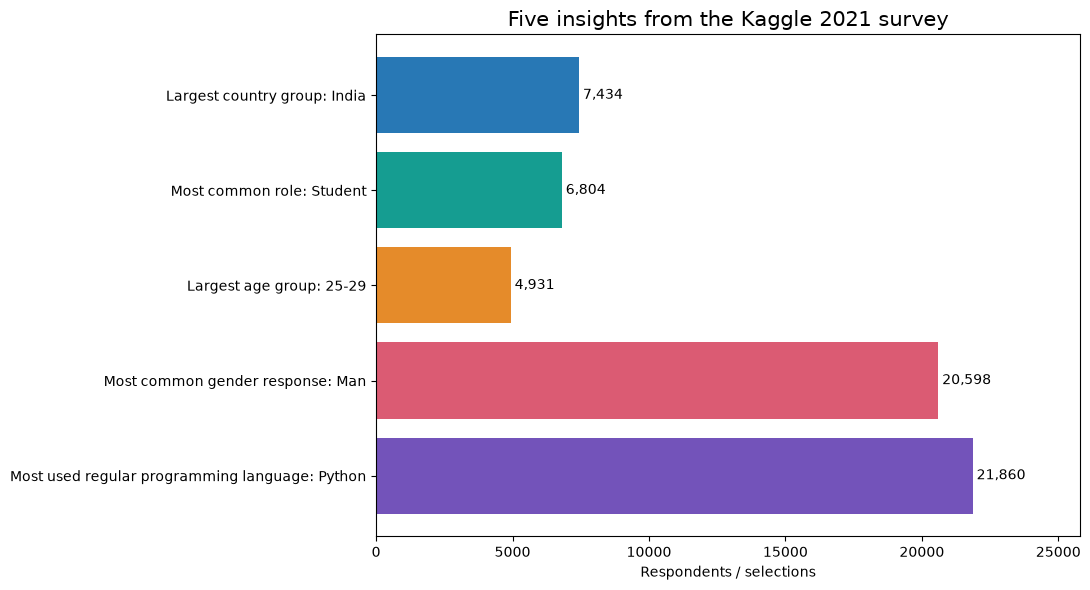

In [11]:
plt.figure(figsize=(11, 6))
bars = plt.barh(insights["Insight"], insights["Responses / selections"], color=["#2878B5", "#159d91", "#e58b2a", "#db5b73", "#7353ba"])
plt.gca().invert_yaxis()
plt.title("Five insights from the Kaggle 2021 survey", fontsize=15)
plt.xlabel("Respondents / selections")
plt.ylabel("")
for position, value in enumerate(insights["Responses / selections"]):
    plt.text(value, position, f" {value:,}", va="center")
plt.xlim(0, insights["Responses / selections"].max() * 1.18)
plt.tight_layout()
plt.show()

## 8. Save the cleaned survey

Save the cleaned working copy as a new CSV. The Kaggle source file remains unchanged. This output still contains blank survey answers; the cleaning standardized formatting and removed exact duplicates without fabricating values.

In [12]:
cleaned_file = Path("kaggle_survey_2021_cleaned.csv")
clean.to_csv(cleaned_file, index=False)
print("Saved cleaned file:", cleaned_file.resolve())
print("Final cleaned shape:", clean.shape)

Saved cleaned file: C:\Users\Fawzy\Documents\Codex\2026-10-22\files-mentioned-by-the-user-data\outputs\Elevvo_Data_Analytics_Portfolio\task-04-survey-insights\kaggle_survey_2021_cleaned.csv
Final cleaned shape: (25973, 370)


## Conclusion

- The source includes a question-wording row, which was excluded from respondent counts.
- Exact duplicate records were checked; any duplicates are removed and the observed count is displayed above.
- Extra whitespace in text answers is standardized.
- Missing answers are retained because blank cells may result from conditional survey logic.
- Categorical labels stay readable, with a documented gender-text standardization.
- Tables and charts summarize respondent profile and programming-language use.
- The final chart shows five computed insights as required by the task bonus.

**Interpretation limit:** this was a voluntary Kaggle survey. It describes participants who answered and should not be presented as representative of all data science professionals.

### Source

[Official 2021 Kaggle Machine Learning & Data Science Survey](https://www.kaggle.com/competitions/kaggle-survey-2021/data).